<a href="https://colab.research.google.com/github/saanvijain08ind-sys/unmix/blob/main/signal_ica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os

# Create folders for structured audio deliverables
os.makedirs("data/sources", exist_ok=True)
os.makedirs("data/mixed", exist_ok=True)
os.makedirs("data/separated", exist_ok=True)
os.makedirs("assets", exist_ok=True)
print("Project structure initialized!")

Project structure initialized!


In [2]:
import numpy as np
from scipy.io import wavfile
import matplotlib.pyplot as plt
from IPython.display import Audio, display

sample_rate = 22050
duration = 4.0  # seconds
num_samples = int(sample_rate * duration)
t = np.linspace(0, duration, num_samples, endpoint=False)

# 1. Generate 3 distinct, non-Gaussian source signals
# Source 1: Harmonic sinusoidal tone (Speech/music fundamental)
s1 = np.sin(2 * np.pi * 330 * t) + 0.5 * np.sin(2 * np.pi * 660 * t)

# Source 2: Modulated acoustic signal (Tremolo/Chime)
s2 = np.sin(2 * np.pi * 550 * t) * np.sin(2 * np.pi * 4 * t)

# Source 3: Non-smooth square wave (High kurtosis, ambient buzz)
s3 = np.sign(np.sin(2 * np.pi * 120 * t)) * 0.4

# Stack into source matrix S: Shape (m, N)
S = np.vstack([s1, s2, s3])
m, N = S.shape

# Normalize each source to [-1.0, 1.0] and write to disk
for i in range(m):
    S[i] = S[i] / np.max(np.abs(S[i]))
    wavfile.write(f"data/sources/source_{i+1}.wav", sample_rate, S[i].astype(np.float32))

# 2. Define an invertible mixing matrix A (shape m x m)
np.random.seed(42)
A = np.array([
    [0.55, 0.25, 0.20],
    [0.30, 0.50, 0.20],
    [0.15, 0.25, 0.60]
])

# Ensure A is invertible (det != 0)
assert np.linalg.det(A) != 0, "Matrix A must be invertible!"

# Compute mixed signals X = A * S
X = np.dot(A, S)

# Normalize and write mixed signals
for i in range(m):
    norm_mix = X[i] / np.max(np.abs(X[i]))
    wavfile.write(f"data/mixed/mixed_{i+1}.wav", sample_rate, norm_mix.astype(np.float32))

print(f"Sources and Mixtures generated: {m} channels across {N} samples.")
display(Audio("data/mixed/mixed_1.wav"))

Sources and Mixtures generated: 3 channels across 88200 samples.


In [3]:
# --- 1. Centering ---
# Subtract empirical mean of each row
X_mean = np.mean(X, axis=1, keepdims=True)
X_centered = X - X_mean

# --- 2. PCA Whitening (Sphering) ---
# Sample Covariance Sigma = (1 / (N - 1)) * X_centered * X_centered^T
Sigma = np.cov(X_centered)

# Eigendecomposition: Sigma = E * D * E^T
eigenvalues, E = np.linalg.eigh(Sigma)

# Construct whitening matrix V = D^(-1/2) * E^T
# np.linalg.eigh sorts eigenvalues in ascending order
D_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(eigenvalues, 1e-12)))
V = np.dot(D_inv_sqrt, E.T)

# Project onto whitened space
X_white = np.dot(V, X_centered)

# Verification check: The covariance of X_white should be the Identity Matrix (I)
white_cov = np.cov(X_white)
print("Covariance of Whitened Data (should be close to Identity):")
print(np.round(white_cov, 3))
assert np.allclose(white_cov, np.eye(m), atol=1e-2), "Whitening failed to produce identity covariance!"

Covariance of Whitened Data (should be close to Identity):
[[ 1.  0. -0.]
 [ 0.  1. -0.]
 [-0. -0.  1.]]


In [4]:
def fast_ica_from_scratch(X_w, n_components, max_iter=500, tol=1e-6):
    """
    Fixed-point FastICA implementation using Gram-Schmidt deflationary orthogonalization.
    """
    m, num_samples = X_w.shape
    W = np.zeros((n_components, m))

    for p in range(n_components):
        # Initialize random unit vector
        w = np.random.randn(m)
        w /= np.linalg.norm(w)

        for iteration in range(max_iter):
            # Projection: u = w^T * X_white (shape: 1 x N)
            u = np.dot(w, X_w)

            # Contrast function evaluations
            g_u = np.tanh(u)
            g_prime_u = 1.0 - g_u**2

            # FastICA Fixed-point step: E[X * g(w^T * X)] - E[g'(w^T * X)] * w
            w_new = np.mean(X_w * g_u, axis=1) - np.mean(g_prime_u) * w

            # Gram-Schmidt Deflationary Orthogonalization against all prior components
            for j in range(p):
                w_new -= np.dot(w_new, W[j]) * W[j]

            # Re-normalize
            w_new /= np.linalg.norm(w_new)

            # Check convergence: |w_new . w| -> 1
            if np.abs(np.abs(np.dot(w_new, w)) - 1.0) < tol:
                w = w_new
                break

            w = w_new

        W[p] = w

    return W

# Execute FastICA
np.random.seed(10)
W_unmix = fast_ica_from_scratch(X_white, n_components=m)

# Recover independent sources: S_hat = W * X_white
S_recovered = np.dot(W_unmix, X_white)

# Normalize recovered tracks to [-1.0, 1.0] and export to disk
for i in range(m):
    rec_norm = S_recovered[i] / np.max(np.abs(S_recovered[i]))
    wavfile.write(f"data/separated/recovered_{i+1}.wav", sample_rate, rec_norm.astype(np.float32))

print("FastICA separation successfully executed!")

FastICA separation successfully executed!


In [5]:
# Absolute Pearson Correlation Matrix
corr_matrix = np.zeros((m, m))
for i in range(m):
    for j in range(m):
        corr_matrix[i, j] = np.abs(np.corrcoef(S_recovered[i], S[j])[0, 1])

print("Absolute Pearson Correlation Matrix (Recovered vs Original):")
print(np.round(corr_matrix, 3))

# Greedy bipartite alignment based on maximum correlation
matched_pairs = {}
for i in range(m):
    best_source_idx = np.argmax(corr_matrix[i])
    best_score = corr_matrix[i, best_source_idx]
    matched_pairs[i] = (best_source_idx, best_score)
    print(f"Recovered Component {i+1} maps to Original Source {best_source_idx+1} with Correlation: {best_score:.4f}")

# Calculate Signal-to-Distortion Ratio (SDR) proxy in dB for aligned signals
def calculate_sdr(ref, est):
    # Adjust for potential sign flip
    if np.corrcoef(ref, est)[0, 1] < 0:
        est = -est
    # Optimal scaling factor alpha
    alpha = np.dot(ref, est) / np.dot(est, est)
    s_target = alpha * est
    e_interf = ref - s_target
    sdr = 10 * np.log10(np.sum(ref**2) / np.sum(e_interf**2))
    return sdr

for rec_idx, (orig_idx, _) in matched_pairs.items():
    sdr_val = calculate_sdr(S[orig_idx], S_recovered[rec_idx])
    print(f"SDR for Source {orig_idx+1}: {sdr_val:.2f} dB")

Absolute Pearson Correlation Matrix (Recovered vs Original):
[[0.003 0.    1.   ]
 [1.    0.    0.   ]
 [0.    1.    0.   ]]
Recovered Component 1 maps to Original Source 3 with Correlation: 1.0000
Recovered Component 2 maps to Original Source 1 with Correlation: 1.0000
Recovered Component 3 maps to Original Source 2 with Correlation: 1.0000
SDR for Source 3: 59.92 dB
SDR for Source 1: 49.41 dB
SDR for Source 2: 77.97 dB


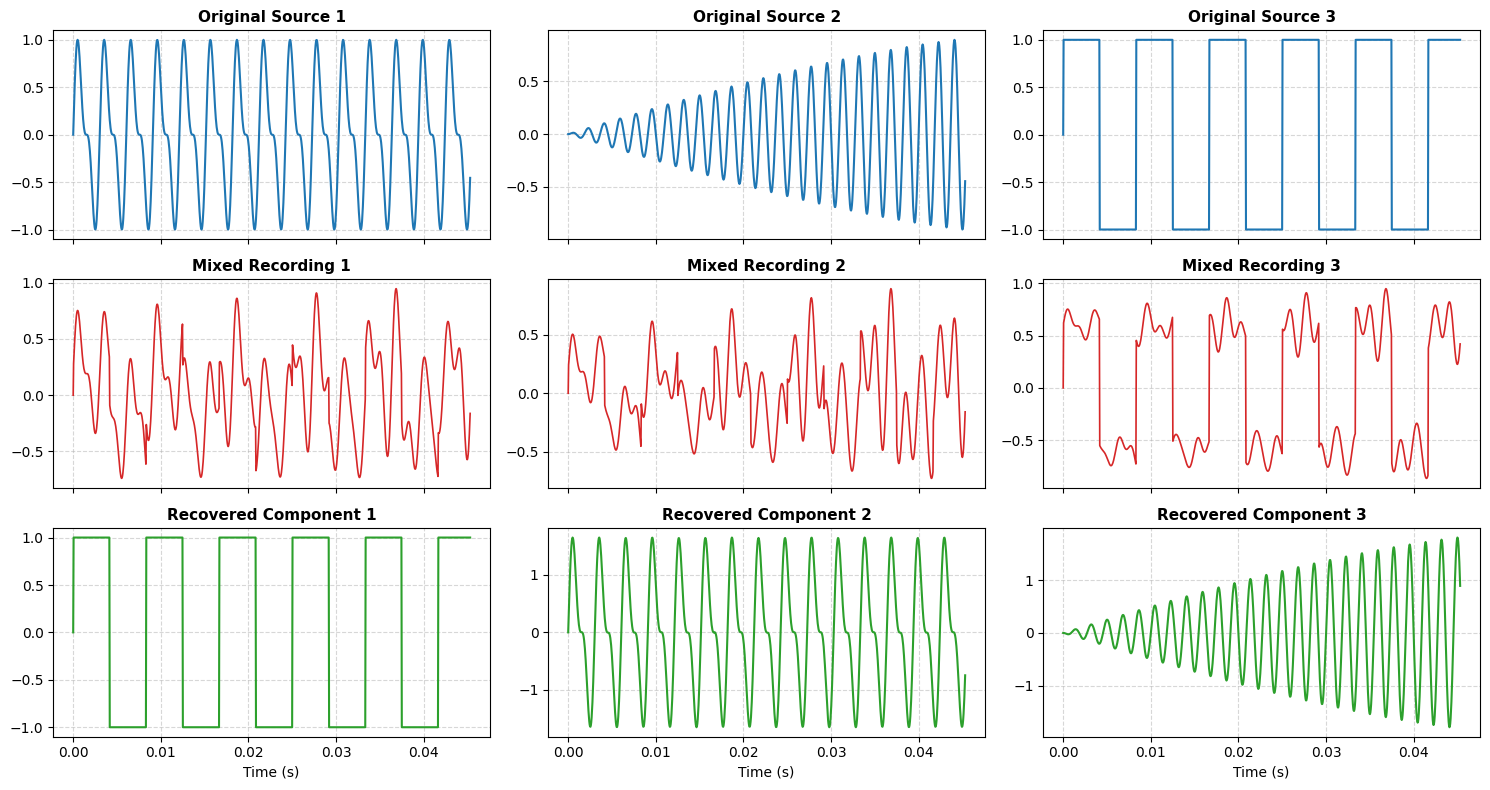

Saved comparison chart to assets/comparison.png


In [6]:
fig, axes = plt.subplots(3, m, figsize=(15, 8), sharex=True)

# Plot a window of 1000 samples for high-clarity waveform inspection
plot_window = 1000

for i in range(m):
    # Row 1: Original Sources
    axes[0, i].plot(t[:plot_window], S[i][:plot_window], color='#1f77b4', lw=1.5)
    axes[0, i].set_title(f"Original Source {i+1}", fontsize=11, fontweight='bold')
    axes[0, i].grid(True, linestyle='--', alpha=0.5)

    # Row 2: Observed Mixtures
    axes[1, i].plot(t[:plot_window], X[i][:plot_window], color='#d62728', lw=1.2)
    axes[1, i].set_title(f"Mixed Recording {i+1}", fontsize=11, fontweight='bold')
    axes[1, i].grid(True, linestyle='--', alpha=0.5)

    # Row 3: Separated Signals
    axes[2, i].plot(t[:plot_window], S_recovered[i][:plot_window], color='#2ca02c', lw=1.5)
    axes[2, i].set_title(f"Recovered Component {i+1}", fontsize=11, fontweight='bold')
    axes[2, i].grid(True, linestyle='--', alpha=0.5)
    axes[2, i].set_xlabel("Time (s)")

plt.tight_layout()
plt.savefig("assets/comparison.png", dpi=250)
plt.show()
print("Saved comparison chart to assets/comparison.png")